# Compare candidate schedules across a geological ensemble

**Question:** Does the plan with the highest forecast NPV also have the strongest P10 across the same correlated realisations?

**Level:** 2 · The method in practice

**Prerequisites:** Complete uncertainty level 1 first.

**Reading time:** 24 minutes

## Objectives

This lesson compares candidate schedules before geological outcomes are observed. It separates expected return from downside P10, and it distinguishes selection among a finite set of plans from re-optimizing after information arrives. Each schedule comes from a separate OreBlocks method call on the same generated instance. Every plan is evaluated against the same seeded value realisations, so differences are paired by scenario rather than confounded by different random draws. This is still scenario analysis, not a stochastic program: plans are fixed before scoring, the ensemble is synthetic, and it has no drillhole conditioning. By the end, interpret why the best plan by mean and the best by P10 may diverge, and state what further evidence a real mine decision needs.

## Setup

From the repository root, install the pinned environment once with `pip install oreblocks==0.6.5 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2`. This notebook does not install packages; the import cell reports active versions. `oreblocks==0.6.5`.

```bash
pip install oreblocks==0.6.5 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2
```

In [1]:
# Import the documented pipeline and methods; report active versions.
import importlib.metadata as metadata
import sys
from pathlib import Path
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case, DepositSpec, Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
for package in ('oreblocks', 'numpy', 'scipy', 'matplotlib'):
    print(package, metadata.version(package))

oreblocks 0.6.5
numpy 2.5.1
scipy 1.18.1
matplotlib 3.11.2


## Data

PhaseFlow's MIT-licensed teaching pipeline builds a declared synthetic vein: dimensions 4×4×3, seed 31, four periods, and an 8% discount rate. It constructs values, resource coefficients, coordinates, and precedence. No MineLib values are modified. OreBlocks 0.6.5 supplies scheduling and uncertainty methods. The value ensemble is a seeded, spatially correlated lognormal stress generator, not observed geology or a conditionally simulated block model. Its 24 equally weighted draws are reproducible below. Keep this provenance attached to every interpretation: synthetic draws show behavior under stated assumptions, not how likely those assumptions are at a real operation.

## Method



The ensemble contains equally weighted realisations, so the arithmetic mean and empirical P10 are direct summaries of this finite experiment. P10 is not a worst-case guarantee, and with 24 draws it has limited tail resolution. The package's `value_of_plan_selection` would measure the expected gain from seeing a draw and then choosing the best of only the listed fixed plans. It is not an information-perfect optimum and must not be called EVPI. This notebook only re-scores fixed candidates. Companion lesson 03 measures a lower bound on replanning value by searching from one best ex-ante policy on every draw. A per-draw maximum over this menu is a diagnostic oracle, never the replanning baseline; EVPI still requires globally optimal per-draw recourse.

### Step 1: build the declared input



In [2]:
# Declare a reproducible case and construct its validated instance.
case = Case(
    id='uncertainty-vein-4x4x3', category='teaching',
    title_en='Small synthetic vein', title_es='Veta sintetica pequena',
    deposit=DepositSpec(kind='twin', archetype='vein', dims=(4, 4, 3), seed=31),
    scenario=Scenario(
        periods=4, discount_rate=0.08, capacity_fraction=(0.70, 0.50),
        resource_names=('mining', 'processing'),
    ),
)
instance = build_instance(case)
print('contract accepted:', instance.report.ok, '| blocks:', instance.n_blocks)

contract accepted: True | blocks: 48


### Step 2: solve the deterministic reference



In [3]:
# Compute a feasible candidate with the expected strategy.
schedule, _ = ob.solve_cpit(
    instance.cpit, instance.precedence,
    method='expected', local_search=False,
)
print(schedule.method, '| NPV:', round(schedule.npv, 2))

toposort:expected[r1] | NPV: 179191.57


### Step 3: add a topological greedy candidate

The greedy method uses a different priority rule while respecting the precedence graph. Its deterministic NPV is not a risk measure; we retain the full result to score exactly the returned assignment later.

In [4]:
# Compute a feasible candidate with the greedy strategy.
toposort_greedy, _ = ob.solve_cpit(
    instance.cpit, instance.precedence,
    method='greedy', local_search=False,
)
print(toposort_greedy.method, '| NPV:', round(toposort_greedy.npv, 2))

toposort:greedy | NPV: 179593.14


### Step 4: add a locally refined candidate

Local search attempts improving feasible moves from an expected-value schedule. It is a heuristic, not a certificate of global optimality. If two methods return the same schedule here, that is a result of this small instance, not proof that their strategies are equivalent.

In [5]:
# Compute a feasible candidate with the expected strategy.
expected, _ = ob.solve_cpit(
    instance.cpit, instance.precedence,
    method='expected', local_search=True,
)
print(expected.method, '| NPV:', round(expected.npv, 2))

toposort:expected[r1]+shift-ls | NPV: 179191.57


### Step 5: include the literature-backed window method

The window strategy contributes a third sequencing rule. We run it once on base values and freeze its assignment across all draws. This isolates robustness of a preselected schedule; it does not measure how much adapting a plan after observing geology would be worth.

In [6]:
# Build the LP guide, then run the published window heuristic.
window_relaxation = ob.cpit_lp_relaxation(
    instance.cpit, instance.precedence, resource=0,
)
sliding_window = ob.sliding_window_schedule(
    instance.cpit, instance.precedence, window=2, fix=1,
    node_limit=50, mip_gap=0.01, relaxation=window_relaxation,
)
print(sliding_window.method, '| NPV:', round(sliding_window.npv, 2))

sliding-window(w=2,f=1) | NPV: 237344.67


### Step 6: create correlated value draws



In [7]:
# Generate correlated value draws without changing tonnage or capacity.
ensemble = ob.perturb_values(
    instance.cpit.value, instance.x, instance.y, instance.level,
    n=24, sigma=0.25, correlation_blocks=2.0, seed=19,
)
print('draws:', ensemble.n_realisations, '| sigma:', ensemble.sigma)
print(ensemble.note)

draws: 24 | sigma: 0.25
SYNTHETIC geological uncertainty: a seeded lognormal multiplicative perturbation of the block values with a spatially correlated field, NOT a conditional simulation with drillhole data behind it.


### Step 7: score the fixed decision



In [8]:
# Compare the named plans on identical value realisations.
schedules = {
    'expected-base': schedule.period_of_block,
    toposort_greedy.method: toposort_greedy.period_of_block,
    'expected-local-search': expected.period_of_block,
    sliding_window.method: sliding_window.period_of_block,
}
risk = ob.evaluate_across(instance.cpit, ensemble, schedules)
for name, mean, p10 in zip(risk.method_ids, risk.expected, risk.p10):
    print(name, '| mean:', round(float(mean), 2), '| P10:', round(float(p10), 2))
print('best by mean:', risk.best_by_expected, '| best by P10:', risk.best_by_p10)

expected-base | mean: 173035.23 | P10: 129694.82
toposort:greedy | mean: 172983.1 | P10: 130723.07
expected-local-search | mean: 173035.23 | P10: 129694.82
sliding-window(w=2,f=1) | mean: 232257.98 | P10: 187607.51
best by mean: sliding-window(w=2,f=1) | best by P10: sliding-window(w=2,f=1)


The comparison uses common random numbers: every candidate is scored against the same spatial value fields. This pairing matters because subtracting two averages from independently sampled fields would mix policy differences with sampling noise. For draw j and policy k, the matrix entry is the discounted value of the fixed period assignment under that draw. The mean estimates average performance over this declared synthetic distribution; P10 describes a lower-tail outcome, not a guaranteed floor. A policy can lead on the mean and lose on P10 when it concentrates value in a few high-value blocks that are uncertain.

The sampled geology is a correlated perturbation of the synthetic base values, so neighboring blocks do not behave like independent coin flips. That assumption affects the spread: stronger correlation can create coherent high- or low-value regions and make a schedule's spatial exposure more important. The seed fixes a reproducible experiment, but one seed does not quantify uncertainty about the distribution itself. A practitioner should repeat the comparison over defensible correlation lengths and perturbation scales, then report whether the ranking changes. The interval across those model settings is a sensitivity range, not a statistical confidence interval.

The candidate set is also part of the question. Its best P10 policy is only the best among the schedules generated here; it is not the optimal risk-aware schedule. These scores do not re-optimize after observing a realization, model mining costs beyond the declared value field, or capture a calibrated geological posterior. They help screen plans for downside exposure and identify which blocks drive the risk. A production decision still needs reconciliation against measured geology, cost, recovery, and capacity assumptions before the ranking is treated as operational advice.


## Results

**Answer:** The sliding-window candidate leads both criteria: mean NPV 232257.98 and P10 187607.51 across the 24 shared draws. The finite-menu selection value is 0.00; that says this menu adds no mean value when selecting after a draw in this case, not that information has no value or that EVPI is zero.

In [9]:
# Print the exact quantities used in the answer.
print(f'mean={risk.expected[0]:.2f}; P10={risk.p10[0]:.2f}; P90={risk.p90[0]:.2f}')
print(f'base={risk.mean_model_npv[0]:.2f}; optimism={risk.deterministic_optimism[0]:.2f}')

mean=173035.23; P10=129694.82; P90=226632.30
base=179191.57; optimism=6156.34


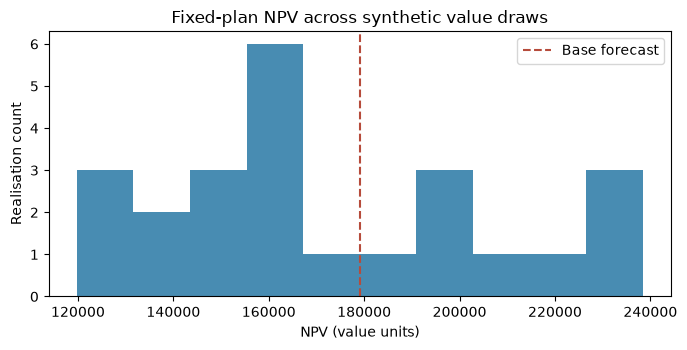

In [10]:
# Plot each computed scenario score and mark the base forecast.
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(risk.matrix[0], bins=10, color='#2878a5', alpha=0.85)
ax.axvline(risk.mean_model_npv[0], color='#b64b3b', linestyle='--', label='Base forecast')
ax.set(
    title='Fixed-plan NPV across synthetic value draws',
    xlabel='NPV (value units)', ylabel='Realisation count',
)
ax.legend()
fig.tight_layout()
plt.show()

### Figure 1

Each bin counts realizations of the fixed forecast schedule within an NPV interval, and the dashed line marks its mean score. The histogram exposes spread and skew for this one policy under the seeded correlated-value generator. It does not compare competing schedules or assign probabilities to outcomes at a real operation. A pronounced lower tail would motivate checking which uncertain blocks and periods drive the exposure.


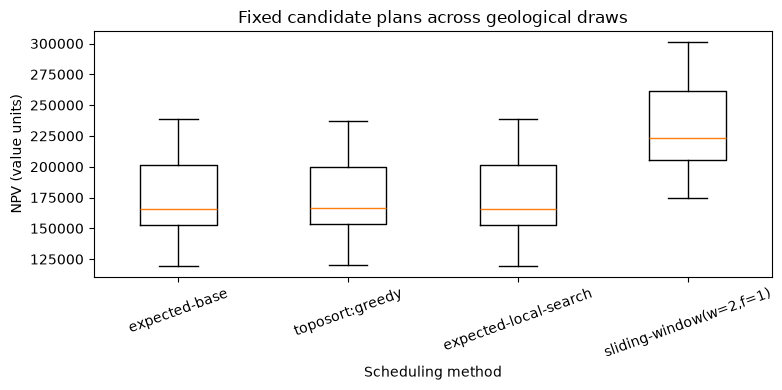

In [11]:
# Plot each plan's full cross-scenario score distribution.
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(risk.matrix.T, tick_labels=risk.method_ids)
ax.set(title='Fixed candidate plans across geological draws', xlabel='Scheduling method', ylabel='NPV (value units)')
ax.tick_params(axis='x', rotation=20)
fig.tight_layout()
plt.show()

### Figure 2

Each box summarizes one candidate's NPV over the same 24 value realizations, so differences between boxes are paired policy comparisons. The median and interquartile range show typical spread, while whiskers and points expose more extreme draws. Overlap is descriptive and is not a significance test. The plot omits schedules outside this candidate set and cannot establish a universally preferred risk measure.


The selected labels and values answer the decision question using the computed candidate set and identical draws.

In [12]:
# Compute the expected-value and lower-tail decision quantities.
print('best by mean:', risk.best_by_expected, round(float(max(risk.expected)), 2))
print('best by P10:', risk.best_by_p10, round(float(max(risk.p10)), 2))
print('finite-plan selection value:', round(risk.value_of_plan_selection, 2))

best by mean: sliding-window(w=2,f=1) 232257.98
best by P10: sliding-window(w=2,f=1) 187607.51
finite-plan selection value: 0.0


## Summary



## References

- PhaseFlow synthetic instance contract and builder: `data-pipeline/pipeline/io/schema.py`, `data-pipeline/pipeline/model/instances.py` (MIT).
- OreBlocks 0.6.5: `oreblocks.perturb_values` and `oreblocks.evaluate_across`.
- Blom, Pearce & Cote: https://arxiv.org/abs/2403.18213.
- Ramazan & Dimitrakopoulos: https://doi.org/10.1007/s11081-012-9186-2.
- Meagher, Dimitrakopoulos & Avis: https://doi.org/10.1134/S1062739114030132.